# May 2025 Revenue Forecast Using Linear Trend Model (Jan–Apr 2025 Data)

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression


# Data Loading and Preparation

In [5]:
df = pd.read_excel("D:\Voltride_Analysis_DecodeX\modified_voltride_dataset_DecodeX.xlsx")
df.head()


<>:1: SyntaxWarning: invalid escape sequence '\V'
<>:1: SyntaxWarning: invalid escape sequence '\V'
C:\Users\TAMILARASU\AppData\Local\Temp\ipykernel_23608\814910607.py:1: SyntaxWarning: invalid escape sequence '\V'
  df = pd.read_excel("D:\Voltride_Analysis_DecodeX\modified_voltride_dataset_DecodeX.xlsx")


,City,Date,Day,Hour,Pickup_Zone,Drop_Zone,Ride_Distance_km,Estimated_Fare,Surge_Multiplier,EV_Battery_%,Driver_Available,Charging_Station_Nearby,Weather,Ride_Status,Cancellation_By,Cancellation_Flag,Completion_Flag,Low_Battery,Peak_Hour
0,Hyderabad,2025-01-01,Wednesday,5,8,3,21.59,374.64,2.0,29,Yes,Yes,Heavy Rain,Completed,Not_Cancelled,0,1,0,0
1,Mumbai,2025-01-01,Wednesday,13,5,4,4.70,353.66,1.0,61,Yes,No,Rain,Completed,Not_Cancelled,0,1,0,0
2,Delhi,2025-01-01,Wednesday,11,5,5,3.52,329.88,2.0,30,Yes,Yes,Clear,Completed,Not_Cancelled,0,1,0,0
3,Bengaluru,2025-01-01,Wednesday,22,9,7,21.28,628.14,2.0,17,Yes,Yes,Clear,Cancelled,System,1,0,1,0
4,Hyderabad,2025-01-01,Wednesday,19,5,2,7.00,526.89,1.5,34,Yes,No,Rain,Completed,Not_Cancelled,0,1,0,1


# we know already it is in Datetime format but to make it proper we do the format conversion process again

In [6]:
df["Date"] = pd.to_datetime(df["Date"])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   City                     2500 non-null   object        
 1   Date                     2500 non-null   datetime64[ns]
 2   Day                      2500 non-null   object        
 3   Hour                     2500 non-null   int64         
 4   Pickup_Zone              2500 non-null   int64         
 5   Drop_Zone                2500 non-null   int64         
 6   Ride_Distance_km         2500 non-null   float64       
 7   Estimated_Fare           2500 non-null   float64       
 8   Surge_Multiplier         2500 non-null   float64       
 9   EV_Battery_%             2500 non-null   int64         
 10  Driver_Available         2500 non-null   object        
 11  Charging_Station_Nearby  2500 non-null   object        
 12  Weather                  2500 non-

## Revenue Calculation

In [7]:
df["Revenue"] = df.apply(
    lambda x: x["Estimated_Fare"] if x["Ride_Status"] == "Completed" else 0,
    axis=1
)

df.head()


,City,Date,Day,Hour,Pickup_Zone,Drop_Zone,Ride_Distance_km,Estimated_Fare,Surge_Multiplier,EV_Battery_%,Driver_Available,Charging_Station_Nearby,Weather,Ride_Status,Cancellation_By,Cancellation_Flag,Completion_Flag,Low_Battery,Peak_Hour,Revenue
0,Hyderabad,2025-01-01,Wednesday,5,8,3,21.59,374.64,2.0,29,Yes,Yes,Heavy Rain,Completed,Not_Cancelled,0,1,0,0,374.64
1,Mumbai,2025-01-01,Wednesday,13,5,4,4.70,353.66,1.0,61,Yes,No,Rain,Completed,Not_Cancelled,0,1,0,0,353.66
2,Delhi,2025-01-01,Wednesday,11,5,5,3.52,329.88,2.0,30,Yes,Yes,Clear,Completed,Not_Cancelled,0,1,0,0,329.88
3,Bengaluru,2025-01-01,Wednesday,22,9,7,21.28,628.14,2.0,17,Yes,Yes,Clear,Cancelled,System,1,0,1,0,0.00
4,Hyderabad,2025-01-01,Wednesday,19,5,2,7.00,526.89,1.5,34,Yes,No,Rain,Completed,Not_Cancelled,0,1,0,1,526.89


# Monthly Revenue Aggregation

In [8]:
df["Month_Number"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.month_name()

monthly_revenue = df.groupby(
    ["Month_Number", "Month_Name"]
)["Revenue"].sum().reset_index()

monthly_revenue = monthly_revenue.sort_values("Month_Number")

monthly_revenue


,Month_Number,Month_Name,Revenue
0,1,January,247593.32
1,2,February,214675.97
2,3,March,235510.24
3,4,April,103836.10


# Time Index Creation

In [9]:
monthly_revenue["Time_Index"] = range(1, len(monthly_revenue) + 1)

monthly_revenue


,Month_Number,Month_Name,Revenue,Time_Index
0,1,January,247593.32,1
1,2,February,214675.97,2
2,3,March,235510.24,3
3,4,April,103836.10,4


# Linear Trend Model Development

In [10]:
X = monthly_revenue[["Time_Index"]]
y = monthly_revenue["Revenue"]

model = LinearRegression()
model.fit(X, y)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


# Forecasting Revenue Equation

In [11]:
intercept = model.intercept_
slope = model.coef_[0]

print(f"Model Equation: Revenue = {intercept:.2f} + ({slope:.2f} × Time_Index)")


Model Equation: Revenue = 303013.26 + (-41043.74 × Time_Index)


# Forecasting Revenue for May 2025

In [12]:
may_index = np.array([[5]])

may_forecast = model.predict(may_index)

print("Predicted Revenue for May 2025:", round(may_forecast[0], 2))


Predicted Revenue for May 2025: 97794.56


c:\Users\TAMILARASU\anaconda3\envs\venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


# Visualization of Forecast

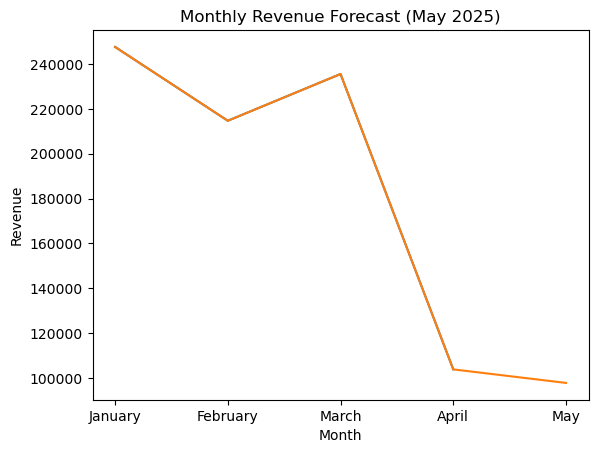

In [ ]:
plt.figure()

# Plot actual data
plt.plot(monthly_revenue["Month_Name"], monthly_revenue["Revenue"])

# Add May forecast to display
extended_months = monthly_revenue["Month_Name"].tolist() + ["May"]
extended_revenue = monthly_revenue["Revenue"].tolist() + [may_forecast[0]]

plt.plot(extended_months, extended_revenue)

plt.title("Monthly Revenue Forecast (May 2025)")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()